# XAI Results Analysis


## Setup


In [13]:
from pathlib import Path
import json
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


RESULTS_DIR = Path("../../results").resolve()

DATASETS = [
    "heart",
    "stroke",
    "diabetes",
    "ckd",
    "hba1c"
]

DISPLAY_NAMES = {
    "heart": "Heart",
    "stroke": "Stroke",
    "diabetes": "Diabetes",
    "ckd": "CKD",
    "hba1c": "HbA1c"
}

ANALYSIS_OUT = RESULTS_DIR / "cross_dataset"

if not RESULTS_DIR.exists():
    raise FileNotFoundError(
        f"Results directory not found: {RESULTS_DIR}"
    )

missing_dataset_dirs = [
    dataset
    for dataset in DATASETS
    if not (RESULTS_DIR / dataset).is_dir()
]

if missing_dataset_dirs:
    raise FileNotFoundError(
        "Missing dataset result directories: "
        + ", ".join(missing_dataset_dirs)
    )

ANALYSIS_OUT.mkdir(parents=True, exist_ok=True)

print("Results directory:", RESULTS_DIR)
print("Analysis output:", ANALYSIS_OUT)

Results directory: C:\Users\catia\Desktop\Blackboard\AASB\github\thesis\results
Analysis output: C:\Users\catia\Desktop\Blackboard\AASB\github\thesis\results\cross_dataset


In [65]:
THESIS_GREEN_DARK = "#5E7D68"
THESIS_GREEN = "#7FAF8F"
THESIS_GREEN_LIGHT = "#B8CDBE"
THESIS_GREY = "#E6E6E6"

THESIS_GREEN_PALETTE = [
    THESIS_GREEN_DARK,
    THESIS_GREEN,
    THESIS_GREEN_LIGHT
]

### Shared loading and validation helpers


In [14]:
def load_metadata(dataset):
    path = RESULTS_DIR / dataset / "bundle" / "metadata.json"

    if not path.exists():
        return {}

    with path.open("r", encoding="utf-8") as file:
        return json.load(file)


def load_global_tables(dataset):
    dataset_dir = RESULTS_DIR / dataset

    native = pd.read_csv(dataset_dir / "native_importance.csv")
    permutation = pd.read_csv(
        dataset_dir / "permutation_importance.csv"
    )
    shap = pd.read_csv(dataset_dir / "shap_importance.csv")

    for name, df, importance_column in [
        ("Native", native, "Importance"),
        ("Permutation", permutation, "Importance"),
        ("SHAP", shap, "MeanAbsSHAP")
    ]:
        required = {"Feature", importance_column}
        missing = required.difference(df.columns)

        if missing:
            raise ValueError(
                f"{dataset} {name} table is missing: "
                f"{sorted(missing)}"
            )

        df.drop(
            df[
                df["Feature"]
                .astype(str)
                .str.lower()
                .isin(["intercept", "const"])
            ].index,
            inplace=True
        )

    return native, permutation, shap


def load_stability_rank(dataset):
    path = RESULTS_DIR / dataset / "stability_rank.csv"
    return pd.read_csv(path) if path.exists() else None


def load_feature_stability(dataset):
    path = RESULTS_DIR / dataset / "stability_summary.csv"
    return pd.read_csv(path) if path.exists() else None

# 1.1 Replication model selection

This notebook records the selected replication model reported by each dataset metadata file. Candidate-model performance and selection decisions must remain supported by the replication notebooks; they cannot be reconstructed from the XAI exports alone.


In [15]:
model_selection_rows = []

for dataset in DATASETS:
    metadata = load_metadata(dataset)
    model_name = metadata.get("model", "Unknown")

    if model_name == "BinaryResultsWrapper":
        model_name = "Statsmodels logistic regression"

    model_selection_rows.append({
        "Dataset": DISPLAY_NAMES[dataset],
        "SelectedModel": model_name,
        "SelectionEvidenceAvailableHere": False
    })

model_selection_df = pd.DataFrame(model_selection_rows)
display(model_selection_df)

,Dataset,SelectedModel,SelectionEvidenceAvailableHere
0,Heart,LogisticRegressionCV,False
1,Stroke,LogisticRegression,False
2,Diabetes,RandomForestClassifier,False
3,CKD,RandomForestClassifier,False
4,HbA1c,Statsmodels logistic regression,False


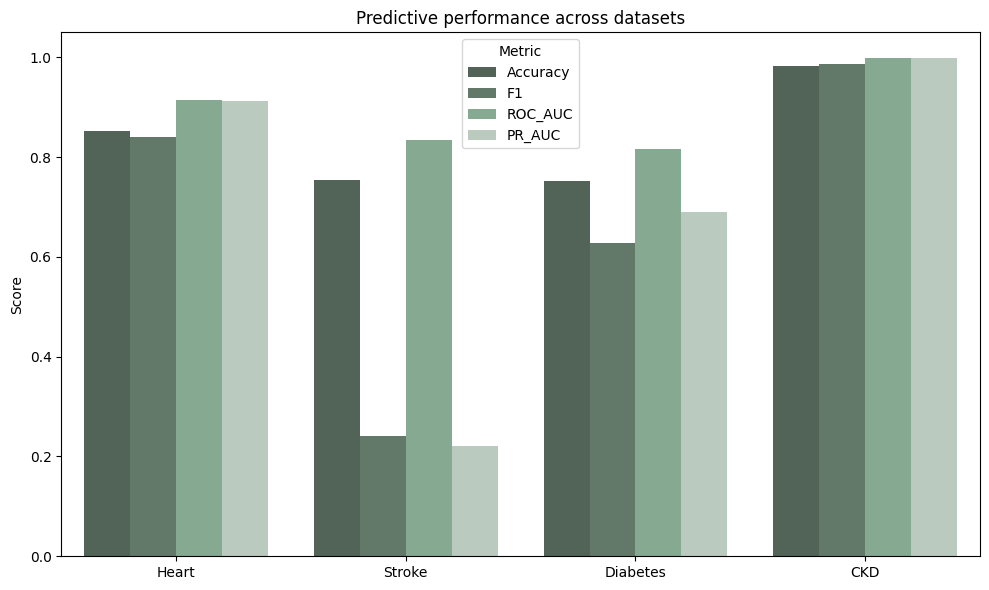

In [70]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

performance_df = pd.DataFrame({
    "Dataset": ["Heart", "Stroke", "Diabetes", "CKD"],
    "Accuracy": [0.852, 0.754, 0.752, 0.983],
    "F1": [0.841, 0.242, 0.627, 0.987],
    "ROC_AUC": [0.915, 0.834, 0.816, 0.999],
    "PR_AUC": [0.912, 0.220, 0.689, 0.999]
})

plot_df = performance_df.melt(
    id_vars="Dataset",
    var_name="Metric",
    value_name="Value"
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=plot_df,
    x="Dataset",
    y="Value",
    hue="Metric",
    palette=[
        "#4F6656",  # darker than #5E7D68
        "#5E7D68",  # dark green
        "#7FAF8F",  # medium green
        "#B8CDBE"   # light green
    ]
)

plt.ylim(0, 1.05)
plt.title("Predictive performance across datasets")
plt.ylabel("Score")
plt.xlabel("")
plt.legend(title="Metric")
plt.tight_layout()
plt.show()

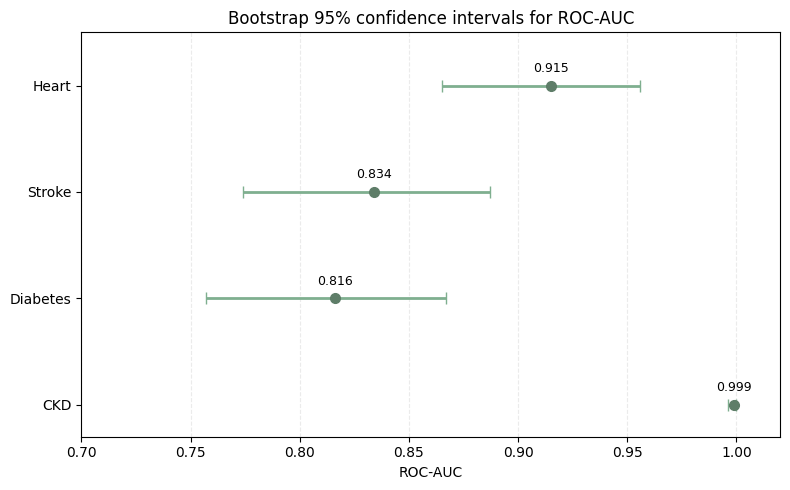

In [73]:
import pandas as pd
import matplotlib.pyplot as plt

uncertainty_df = pd.DataFrame({
    "Dataset": ["Heart", "Stroke", "Diabetes", "CKD"],
    "ROC_AUC": [0.915, 0.834, 0.816, 0.999],
    "ROC_AUC_low": [0.865, 0.774, 0.757, 0.996],
    "ROC_AUC_high": [0.956, 0.887, 0.867, 1.000]
})

plt.figure(figsize=(8, 5))

plot_df = uncertainty_df.iloc[::-1].reset_index(drop=True)

x = plot_df["ROC_AUC"]

xerr = [
    x - plot_df["ROC_AUC_low"],
    plot_df["ROC_AUC_high"] - x
]

plt.errorbar(
    x,
    range(len(plot_df)),
    xerr=xerr,
    fmt="o",
    color="#5E7D68",
    ecolor="#7FAF8F",
    elinewidth=2,
    capsize=4,
    markersize=7
)

plt.yticks(
    range(len(plot_df)),
    plot_df["Dataset"]
)

plt.xlabel("ROC-AUC")
plt.title("Bootstrap 95% confidence intervals for ROC-AUC")
plt.xlim(0.70, 1.02)
plt.ylim(-0.3, len(plot_df) - 0.5)

plt.grid(
    axis="x",
    linestyle="--",
    alpha=0.25
)

for i, value in enumerate(plot_df["ROC_AUC"]):
    plt.text(
        value,
        i + 0.10,
        f"{value:.3f}",
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.tight_layout()
plt.show()

# 1.2 Global XAI results per dataset

Intercept or constant terms are excluded consistently. Native, permutation, and SHAP magnitudes remain method-specific; comparisons below use feature ranks and top-feature membership. HbA1c features are Patsy design-matrix terms, including categorical contrasts and interactions.


In [18]:
def global_rank_table(dataset):
    native, permutation, shap = load_global_tables(dataset)

    native_df = native[["Feature", "Importance"]].rename(
        columns={"Importance": "NativeImportance"}
    )
    permutation_df = permutation[["Feature", "Importance"]].rename(
        columns={"Importance": "PermutationImportance"}
    )
    shap_df = shap[["Feature", "MeanAbsSHAP"]].rename(
        columns={"MeanAbsSHAP": "SHAPImportance"}
    )

    merged = (
        native_df
        .merge(permutation_df, on="Feature", how="inner")
        .merge(shap_df, on="Feature", how="inner")
    )

    if merged.empty:
        raise ValueError(
            f"{dataset}: no features are shared by all three methods"
        )

    for importance_col, rank_col in [
        ("NativeImportance", "NativeRank"),
        ("PermutationImportance", "PermutationRank"),
        ("SHAPImportance", "SHAPRank")
    ]:
        merged[rank_col] = merged[importance_col].rank(
            ascending=False,
            method="average"
        )

    rank_cols = [
        "NativeRank",
        "PermutationRank",
        "SHAPRank"
    ]
    merged["MeanRank"] = merged[rank_cols].mean(axis=1)
    merged["RankRange"] = (
        merged[rank_cols].max(axis=1)
        - merged[rank_cols].min(axis=1)
    )

    return merged.sort_values(
        ["MeanRank", "Feature"],
        ignore_index=True
    )

In [19]:
global_top5_rows = []
global_overlap_rows = []
common_feature_rows = []
all_global_rank_tables = []

for dataset in DATASETS:
    native, permutation, shap = load_global_tables(dataset)

    method_specs = {
        "Native": (native, "Importance"),
        "Permutation": (permutation, "Importance"),
        "SHAP": (shap, "MeanAbsSHAP")
    }

    top_features = {}

    for method, (df, importance_col) in method_specs.items():
        if len(df) < 5:
            raise ValueError(
                f"{dataset} {method} has fewer than five features"
            )

        top_features[method] = (
            df.nlargest(5, importance_col)["Feature"].tolist()
        )

    for rank in range(5):
        global_top5_rows.append({
            "Dataset": DISPLAY_NAMES[dataset],
            "Rank": rank + 1,
            "Native": top_features["Native"][rank],
            "Permutation": top_features["Permutation"][rank],
            "SHAP": top_features["SHAP"][rank]
        })

    native_set = set(top_features["Native"])
    permutation_set = set(top_features["Permutation"])
    shap_set = set(top_features["SHAP"])
    common = native_set & permutation_set & shap_set

    global_overlap_rows.append({
        "Dataset": DISPLAY_NAMES[dataset],
        "Native_SHAP_Top5_Overlap": len(native_set & shap_set) / 5,
        "Native_Permutation_Top5_Overlap": (
            len(native_set & permutation_set) / 5
        ),
        "SHAP_Permutation_Top5_Overlap": (
            len(shap_set & permutation_set) / 5
        ),
        "N_Common_All_Three": len(common)
    })

    common_feature_rows.append({
        "Dataset": DISPLAY_NAMES[dataset],
        "CommonTop5Features": ", ".join(sorted(common)),
        "NCommon": len(common)
    })

    rank_table = global_rank_table(dataset).copy()
    rank_table.insert(0, "Dataset", DISPLAY_NAMES[dataset])
    all_global_rank_tables.append(rank_table)

global_top5_df = pd.DataFrame(global_top5_rows)
global_overlap_df = pd.DataFrame(global_overlap_rows)
common_global_features_df = pd.DataFrame(common_feature_rows)
global_rank_all_df = pd.concat(
    all_global_rank_tables,
    ignore_index=True
)

display(global_top5_df)
display(global_overlap_df.round(3))
display(common_global_features_df)

,Dataset,Rank,Native,Permutation,SHAP
0,Heart,1,thal,thal,thal
1,Heart,2,cp,ca,cp
2,Heart,3,exang,sex,exang
3,Heart,4,thalach,thalach,thalach
4,Heart,5,ca,cp,slope
5,Stroke,1,age,age,age
6,Stroke,2,bmi_missing,avg_glucose_level,avg_glucose_level
7,Stroke,3,avg_glucose_level,bmi_missing,hypertension
8,Stroke,4,hypertension,heart_disease,bmi_missing
9,Stroke,5,heart_disease,ever_married_No,heart_disease


,Dataset,Native_SHAP_Top5_Overlap,Native_Permutation_Top5_Overlap,SHAP_Permutation_Top5_Overlap,N_Common_All_Three
0,Heart,0.8,0.8,0.6,3
1,Stroke,1.0,0.8,0.8,4
2,Diabetes,1.0,1.0,1.0,5
3,CKD,1.0,0.8,0.8,4
4,HbA1c,0.0,0.0,0.8,0


,Dataset,CommonTop5Features,NCommon
0,Heart,"cp, thal, thalach",3
1,Stroke,"age, avg_glucose_level, bmi_missing, heart_dis...",4
2,Diabetes,"Age, BMI, Glucose, Insulin, SkinThickness",5
3,CKD,"al, pcv, sc, sg",4
4,HbA1c,,0


### 1.2.1 Global importance plots


In [92]:
import textwrap

In [93]:
def wrap_feature_label(label, width=32):
    return "\n".join(
        textwrap.wrap(
            str(label),
            width=width,
            break_long_words=False,
            break_on_hyphens=False
        )
    )

In [100]:
def clean_feature_label(label):
    """
    Make long feature/design-matrix labels easier to read in plots.
    Original feature names remain unchanged in the underlying data.
    """
    label = str(label)

    replacements = {
        "specialty_group[T.": "Specialty: ",
        "age_group3[T.": "Age: ",
        "discharge_group[T.": "Discharge: ",
        "admission_type_group[T.": "Admission type: ",
        "admission_source_group[T.": "Admission source: "
    }

    for old, new in replacements.items():
        label = label.replace(old, new)

    # Convert interaction separator into a clearer visual symbol
    label = label.replace("]:", " × ")

    # Remove remaining Patsy syntax
    label = label.replace("[T.", "")
    label = label.replace("]", "")

    return label


def plot_global_importance_combined(dataset, top_n=5):

    native, permutation, shap = load_global_tables(dataset)

    # ---------------------------------------------------------
    # Prepare Native importance
    # ---------------------------------------------------------
    native = native[
        ["Feature", "Importance"]
    ].copy()

    native["Method"] = "Native"

    native = native.rename(
        columns={
            "Importance": "ImportanceValue"
        }
    )

    # ---------------------------------------------------------
    # Prepare Permutation importance
    # ---------------------------------------------------------
    permutation = permutation[
        ["Feature", "Importance"]
    ].copy()

    permutation["Method"] = "Permutation"

    permutation = permutation.rename(
        columns={
            "Importance": "ImportanceValue"
        }
    )

    # ---------------------------------------------------------
    # Prepare SHAP importance
    # ---------------------------------------------------------
    shap = shap[
        ["Feature", "MeanAbsSHAP"]
    ].copy()

    shap["Method"] = "SHAP"

    shap = shap.rename(
        columns={
            "MeanAbsSHAP": "ImportanceValue"
        }
    )

    # ---------------------------------------------------------
    # Combine all methods
    # ---------------------------------------------------------
    combined = pd.concat(
        [
            native,
            permutation,
            shap
        ],
        ignore_index=True
    )

    # ---------------------------------------------------------
    # Normalize importance WITHIN each method
    #
    # Necessary because Native, Permutation and SHAP values
    # are not on the same numerical scale.
    # ---------------------------------------------------------
    combined["NormalizedImportance"] = (
        combined
        .groupby("Method")["ImportanceValue"]
        .transform(
            lambda x:
                x / x.max()
                if x.max() != 0
                else 0
        )
    )

    # ---------------------------------------------------------
    # Calculate average normalized importance for every feature
    # across the three XAI methods
    # ---------------------------------------------------------
    feature_summary = (
        combined
        .groupby(
            "Feature",
            as_index=False
        )
        .agg(
            MeanNormalizedImportance=(
                "NormalizedImportance",
                "mean"
            )
        )
    )

    # ---------------------------------------------------------
    # Select only the strongest TOP N features overall
    # ---------------------------------------------------------
    top_features = (
        feature_summary
        .nlargest(
            top_n,
            "MeanNormalizedImportance"
        )["Feature"]
        .tolist()
    )

    # Create plotting dataframe FIRST
    plot_df = (
        combined[
            combined["Feature"].isin(top_features)
        ]
        .copy()
    )

    # ---------------------------------------------------------
    # Determine display order
    # ---------------------------------------------------------
    feature_order = (
        feature_summary[
            feature_summary["Feature"].isin(top_features)
        ]
        .sort_values(
            "MeanNormalizedImportance",
            ascending=False
        )["Feature"]
        .tolist()
    )

    plot_df["Feature"] = pd.Categorical(
        plot_df["Feature"],
        categories=feature_order,
        ordered=True
    )

    # ---------------------------------------------------------
    # Clean and wrap labels
    # ---------------------------------------------------------
    plot_df["FeatureLabel"] = (
        plot_df["Feature"]
        .astype(str)
        .apply(clean_feature_label)
        .apply(
            lambda x: wrap_feature_label(
                x,
                width=32
            )
        )
    )

    label_order = [
        wrap_feature_label(
            clean_feature_label(feature),
            width=32
        )
        for feature in feature_order
    ]

    plot_df["FeatureLabel"] = pd.Categorical(
        plot_df["FeatureLabel"],
        categories=label_order,
        ordered=True
    )
    # ---------------------------------------------------------
    # Plot
    # ---------------------------------------------------------
    plt.figure(
        figsize=(
            10,
            max(
                4.5,
                len(feature_order) * 0.65
            )
        )
    )

    sns.barplot(
        data=plot_df,
        x="NormalizedImportance",
        y="FeatureLabel",
        hue="Method",
        hue_order=[
            "Native",
            "Permutation",
            "SHAP"
        ],
        palette=[
            "#5E7D68",
            "#7FAF8F",
            "#B8CDBE"
        ]
    )

    plt.xlabel(
        "Within-method normalized importance"
    )

    plt.ylabel("Feature / design-matrix term")
    
    plt.title(
        f"{DISPLAY_NAMES[dataset]}: "
        "normalized global feature importance across XAI methods"
    )

    plt.xlim(
        0,
        1.05
    )

    plt.grid(
        axis="x",
        linestyle="--",
        alpha=0.20
    )

    plt.legend(
        title="Method",
        bbox_to_anchor=(1.02, 1),
        loc="upper left",
        frameon=False
    )

    plt.tight_layout()

    plt.show()

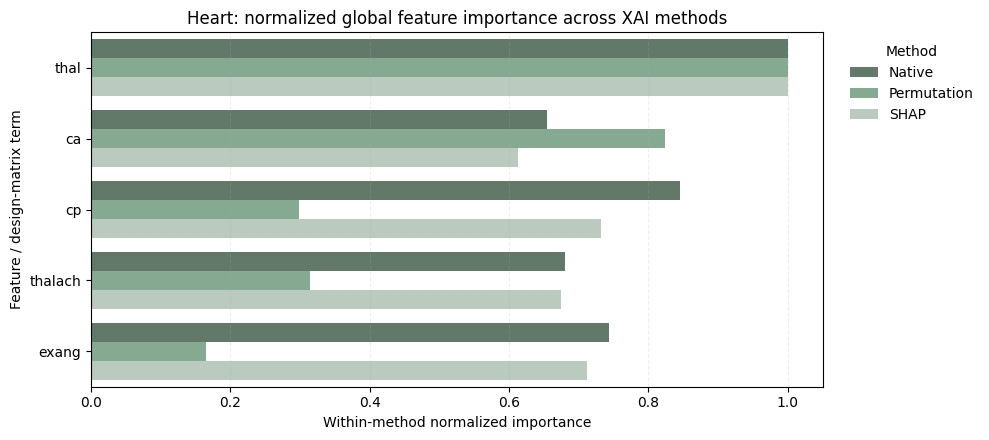

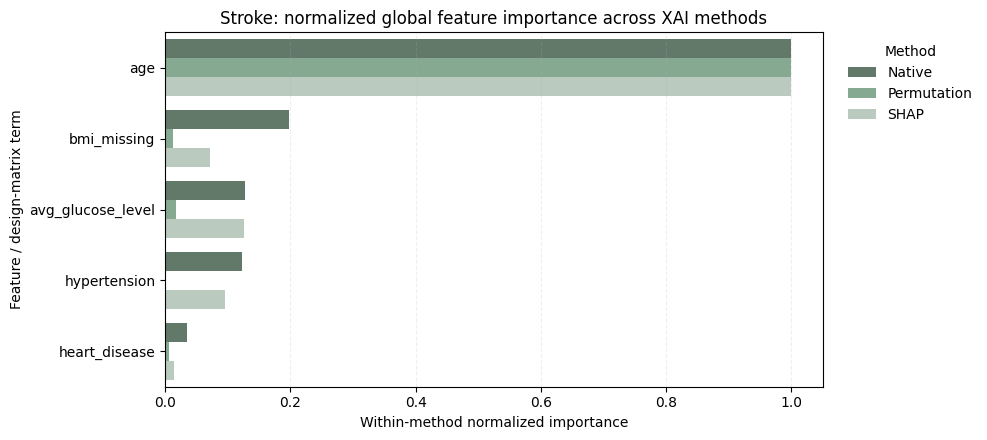

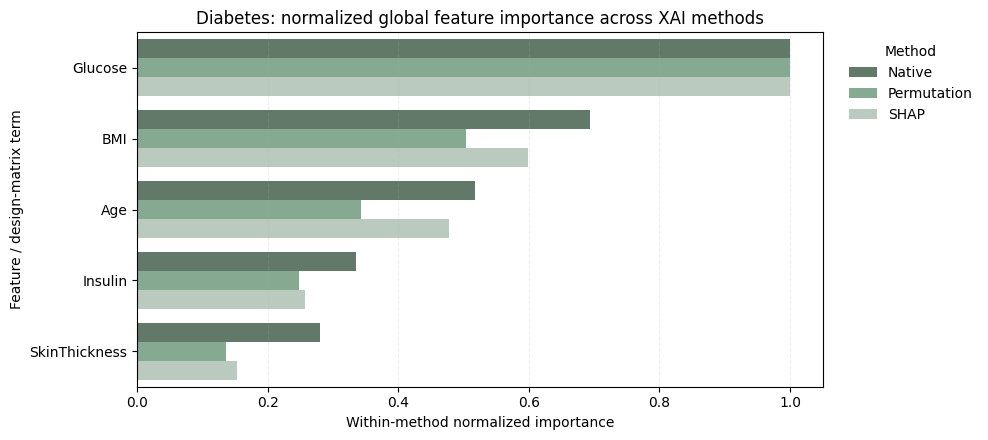

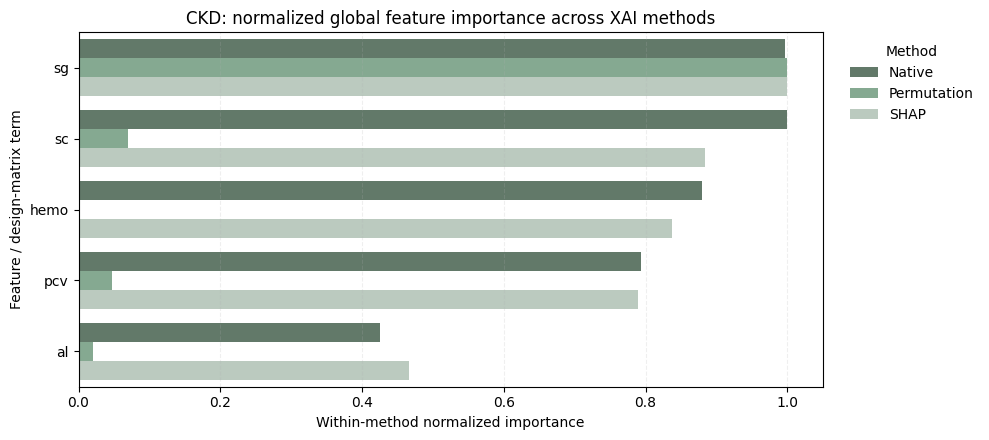

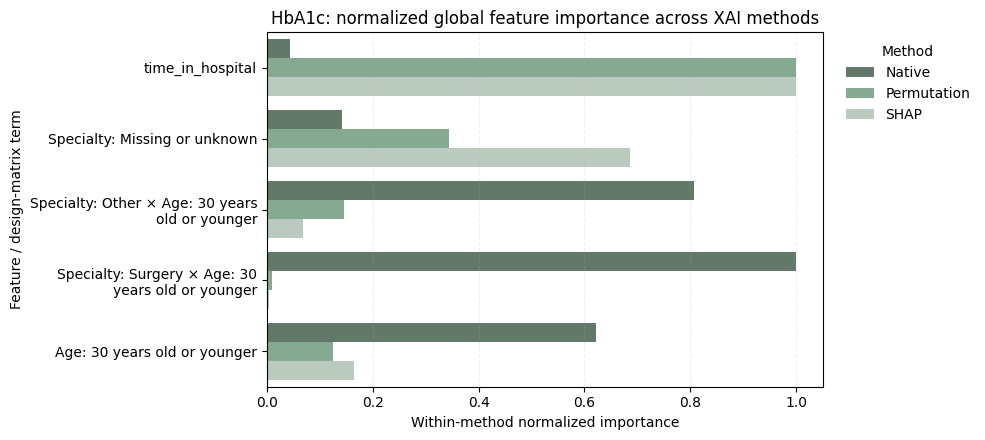

In [101]:
for dataset in DATASETS:

    plot_global_importance_combined(
        dataset,
        top_n=5
    )

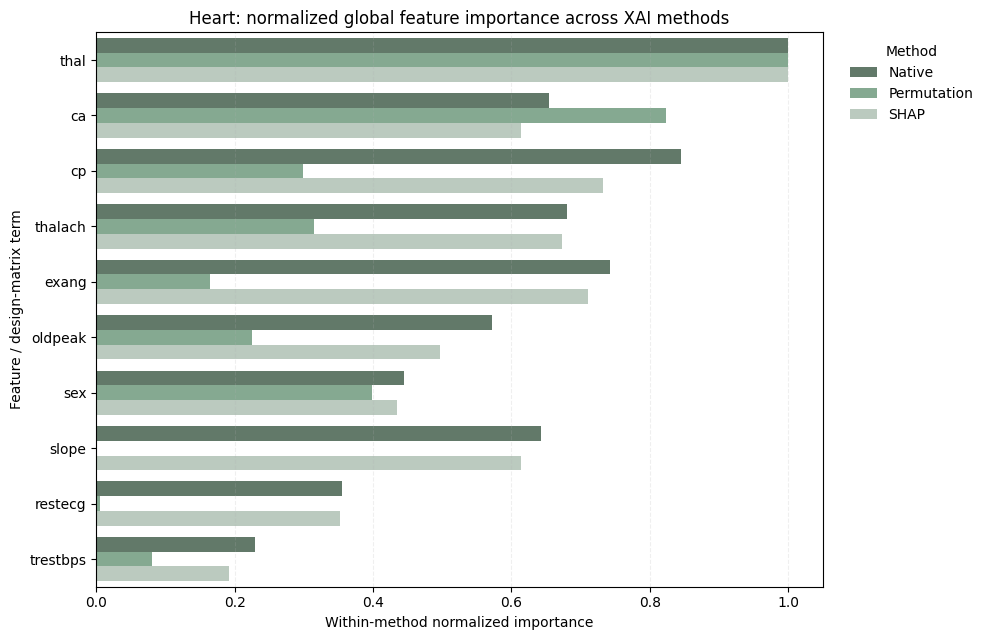

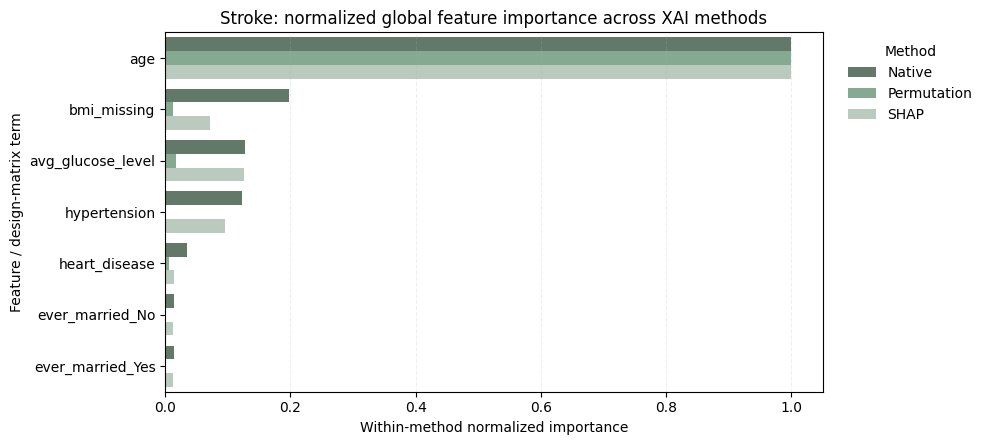

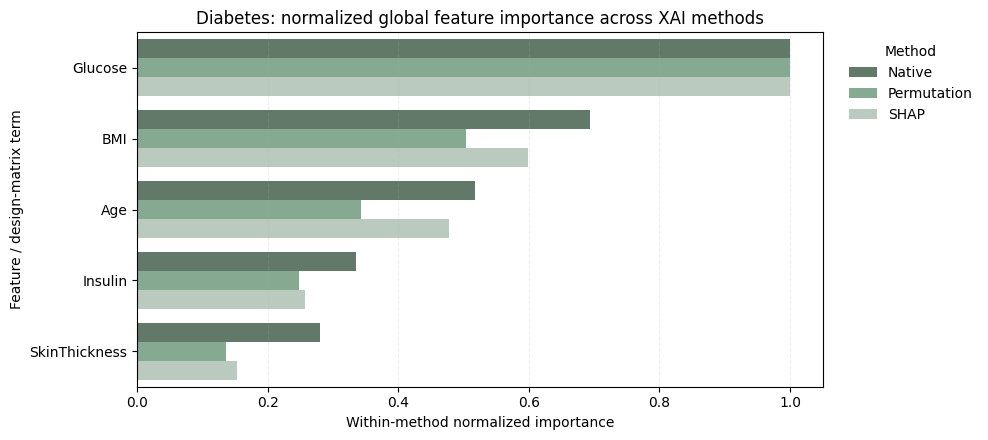

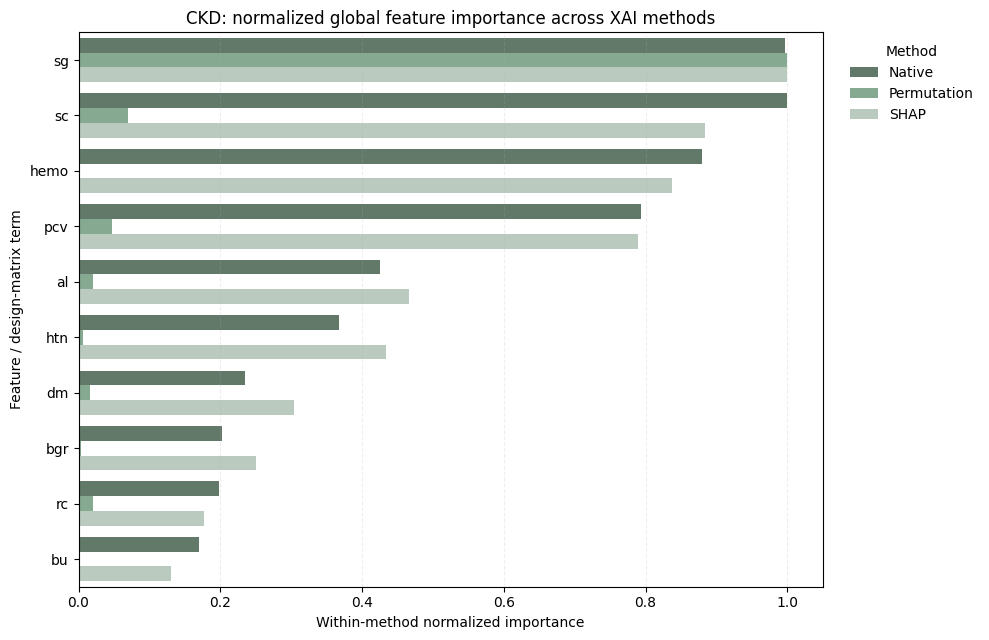

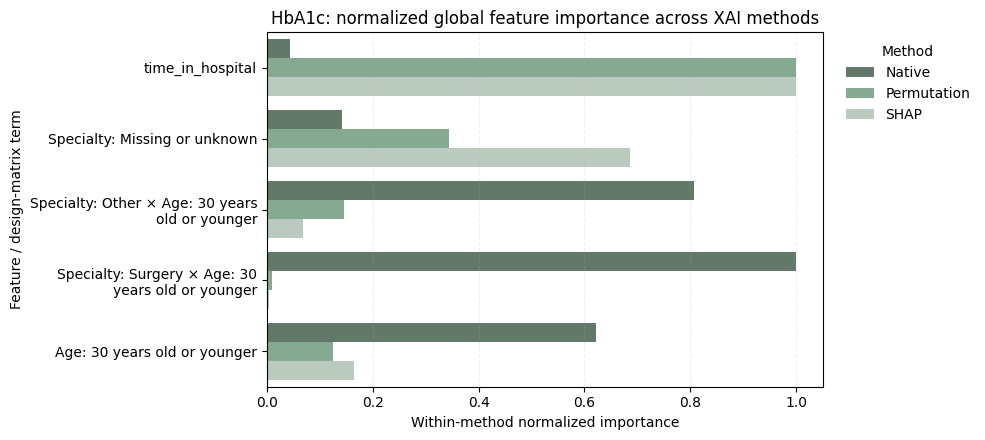

In [102]:
for dataset in DATASETS:

    plot_global_importance_combined(
        dataset,
        top_n=5 if dataset == "hba1c" else 10
    )

### 1.2.2 Export global XAI tables


In [105]:
global_top5_df.to_csv(
    ANALYSIS_OUT / "global_top5_features.csv",
    index=False
)
global_overlap_df.to_csv(
    ANALYSIS_OUT / "global_top5_overlap.csv",
    index=False
)
common_global_features_df.to_csv(
    ANALYSIS_OUT / "global_common_top5_features.csv",
    index=False
)
global_rank_all_df.to_csv(
    ANALYSIS_OUT / "global_rank_comparison_all_features.csv",
    index=False
)


# 1.3 Agreement between XAI methods

Agreement is recalculated from the same intercept-filtered feature set used in section 1.2. The number of compared features is retained because correlation estimates across differently sized feature spaces are not directly equivalent.


,Dataset,Comparison,SpearmanRho,NFeaturesCompared
0,Heart,Native vs SHAP,0.978,13
1,Heart,Native vs Permutation,0.621,13
2,Heart,SHAP vs Permutation,0.615,13
3,Stroke,Native vs SHAP,0.893,7
4,Stroke,Native vs Permutation,0.739,7
5,Stroke,SHAP vs Permutation,0.631,7
6,Diabetes,Native vs SHAP,1.000,5
7,Diabetes,Native vs Permutation,1.000,5
8,Diabetes,SHAP vs Permutation,1.000,5
9,CKD,Native vs SHAP,0.981,24


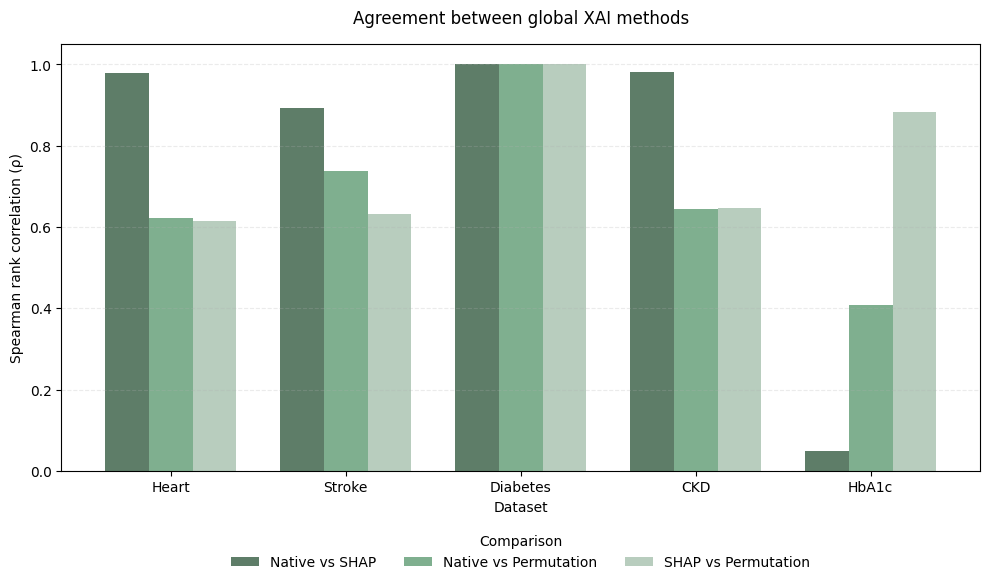

In [106]:
agreement_rows = []

for dataset in DATASETS:

    ranks = global_rank_table(dataset)

    comparisons = {
        "Native vs SHAP": (
            "NativeRank",
            "SHAPRank"
        ),
        "Native vs Permutation": (
            "NativeRank",
            "PermutationRank"
        ),
        "SHAP vs Permutation": (
            "SHAPRank",
            "PermutationRank"
        )
    }

    for comparison, (left, right) in comparisons.items():

        agreement_rows.append({
            "Dataset": DISPLAY_NAMES[dataset],
            "Comparison": comparison,
            "SpearmanRho": ranks[left].corr(
                ranks[right],
                method="spearman"
            ),
            "NFeaturesCompared": len(ranks)
        })


agreement_df = pd.DataFrame(
    agreement_rows
)

display(
    agreement_df.round(3)
)


comparison_order = [
    "Native vs SHAP",
    "Native vs Permutation",
    "SHAP vs Permutation"
]

dataset_order = [
    "Heart",
    "Stroke",
    "Diabetes",
    "CKD",
    "HbA1c"
]

pivot_df = (
    agreement_df
    .pivot(
        index="Dataset",
        columns="Comparison",
        values="SpearmanRho"
    )
    .reindex(
        index=dataset_order,
        columns=comparison_order
    )
)


colors = [
    "#5E7D68",
    "#7FAF8F",
    "#B8CDBE"
]


fig, ax = plt.subplots(
    figsize=(10, 6)
)

pivot_df.plot(
    kind="bar",
    ax=ax,
    color=colors,
    width=0.75
)

ax.set_ylim(
    0,
    1.05
)

ax.set_ylabel(
    "Spearman rank correlation (ρ)"
)

ax.set_xlabel(
    "Dataset"
)

ax.set_title(
    "Agreement between global XAI methods",
    pad=15
)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.25
)

ax.tick_params(
    axis="x",
    rotation=0
)

ax.legend(
    title="Comparison",
    loc="upper center",
    bbox_to_anchor=(0.5, -0.12),
    ncol=3,
    frameon=False
)

plt.tight_layout()
plt.show()


agreement_df.to_csv(
    ANALYSIS_OUT
    / "rank_agreement_all_datasets.csv",
    index=False
)

# 1.4 Stability of explanations

These outputs describe repeated-run permutation-importance stability. Missing stability is reported as unavailable rather than zero. Coefficients of variation should not be interpreted when mean importance is zero or near zero.


,Dataset,MeanStabilityRho,MeanTopKOverlap,NRankComparisons
0,Heart,0.945,0.867,10
1,Stroke,0.825,0.800,10
2,Diabetes,0.940,0.800,10
3,CKD,0.341,0.567,10
4,HbA1c,NaN,NaN,0


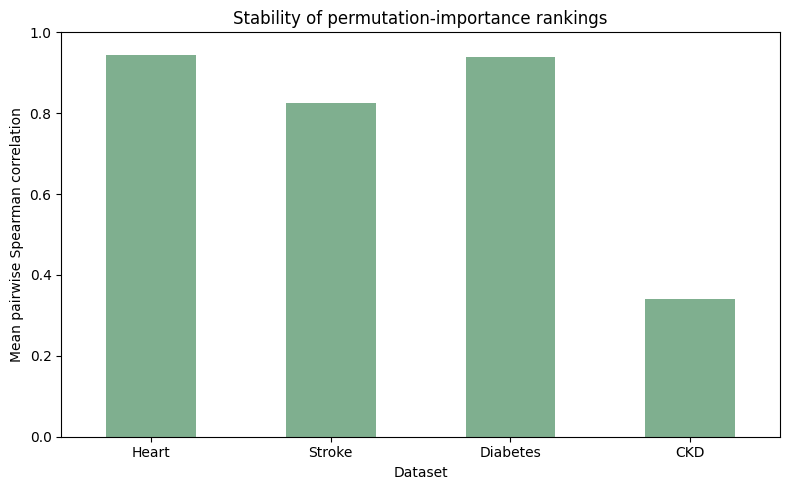

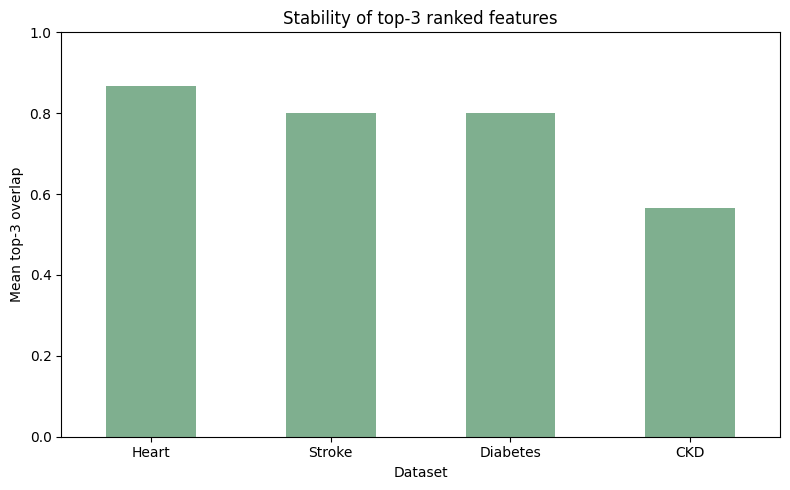

In [111]:
stability_summary_rows = []
feature_stability_frames = []

for dataset in DATASETS:
    rank_df = load_stability_rank(dataset)

    if rank_df is not None and not rank_df.empty:
        stability_summary_rows.append({
            "Dataset": DISPLAY_NAMES[dataset],
            "MeanStabilityRho": (
                rank_df["SpearmanRankCorrelation"].mean()
                if "SpearmanRankCorrelation" in rank_df.columns
                else np.nan
            ),
            "MeanTopKOverlap": (
                rank_df["TopKOverlap"].mean()
                if "TopKOverlap" in rank_df.columns
                else np.nan
            ),
            "NRankComparisons": len(rank_df)
        })
    else:
        stability_summary_rows.append({
            "Dataset": DISPLAY_NAMES[dataset],
            "MeanStabilityRho": np.nan,
            "MeanTopKOverlap": np.nan,
            "NRankComparisons": 0
        })

    feature_df = load_feature_stability(dataset)

    if feature_df is None or feature_df.empty:
        continue

    feature_df = feature_df.copy()
    feature_df.insert(0, "Dataset", DISPLAY_NAMES[dataset])
    feature_df["ImportanceCV"] = np.where(
        feature_df["MeanImportance"].abs() > 1e-12,
        feature_df["StdImportance"]
        / feature_df["MeanImportance"].abs(),
        np.nan
    )
    feature_stability_frames.append(feature_df)

stability_summary_df = pd.DataFrame(stability_summary_rows)

dataset_order = [
    "Heart",
    "Stroke",
    "Diabetes",
    "CKD",
    "HbA1c"
]

stability_summary_df["Dataset"] = pd.Categorical(
    stability_summary_df["Dataset"],
    categories=dataset_order,
    ordered=True
)

stability_summary_df = (
    stability_summary_df
    .sort_values("Dataset")
    .reset_index(drop=True)
)

feature_stability_df = pd.concat(
    feature_stability_frames,
    ignore_index=True
) if feature_stability_frames else pd.DataFrame()

display(stability_summary_df.round(3))

for metric, title, ylabel in [
    (
        "MeanStabilityRho",
        "Stability of permutation-importance rankings",
        "Mean pairwise Spearman correlation"
    ),
    (
        "MeanTopKOverlap",
        "Stability of top-3 ranked features",
        "Mean top-3 overlap"
    )
]:

    plot_data = stability_summary_df.dropna(
        subset=[metric]
    )

    ax = plot_data.plot.bar(
        x="Dataset",
        y=metric,
        legend=False,
        figsize=(8, 5),
        color="#7FAF8F"
    )

    ax.set_ylim(0, 1)
    ax.set_xlabel("Dataset")
    ax.set_ylabel(ylabel)
    ax.set_title(title)

    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

stability_summary_df.to_csv(
    ANALYSIS_OUT / "stability_comparison.csv",
    index=False
)
feature_stability_df.to_csv(
    ANALYSIS_OUT / "feature_level_stability.csv",
    index=False
)


# 1.5 Local explanations and representative cases


### 1.5.1 Representative-case availability and identifier validation


In [24]:
local_case_rows = []
case_map_rows = []

for dataset in DATASETS:
    path = RESULTS_DIR / dataset / "representative_cases.csv"

    if not path.exists():
        continue

    cases = pd.read_csv(path)
    required = {"CaseType", "CaseIndex", "y_true", "y_pred", "y_prob"}
    missing = required.difference(cases.columns)

    if missing:
        raise ValueError(
            f"{dataset} representative cases are missing: "
            f"{sorted(missing)}"
        )

    for _, row in cases.iterrows():
        local_case_rows.append({
            "Dataset": DISPLAY_NAMES[dataset],
            "CaseIndex": row["CaseIndex"],
            "CaseType": row["CaseType"],
            "True": row["y_true"],
            "Predicted": row["y_pred"],
            "Probability": row["y_prob"]
        })
        case_map_rows.append({
            "Dataset": DISPLAY_NAMES[dataset],
            "CaseIndex": row["CaseIndex"],
            "CaseType": row["CaseType"]
        })

local_cases_df = pd.DataFrame(local_case_rows)
case_map_df = pd.DataFrame(case_map_rows)

if case_map_df.duplicated(["Dataset", "CaseIndex"]).any():
    raise ValueError("Representative-case identifiers are not unique")

case_availability = (
    local_cases_df
    .assign(Available=1)
    .pivot_table(
        index="Dataset",
        columns="CaseType",
        values="Available",
        aggfunc="max",
        fill_value=0
    )
    .reset_index()
)

display(local_cases_df.round(4))
display(case_availability)

,Dataset,CaseIndex,CaseType,True,Predicted,Probability
0,Heart,84,TP,1.0,1,0.7621
1,Heart,47,TN,0.0,0,0.2680
2,Heart,95,FP,0.0,1,0.6775
3,Heart,4,FN,1.0,0,0.3640
4,Heart,44,Borderline,0.0,1,0.5001
5,Stroke,207,TP,1.0,1,0.9746
6,Stroke,662,TN,0.0,0,0.0088
7,Stroke,96,FP,0.0,1,0.9864
8,Stroke,553,FN,1.0,0,0.0242
9,Stroke,361,Borderline,0.0,1,0.5004


CaseType,Dataset,Borderline,FN,FP,TN,TP
0,CKD,0,1,1,1,1
1,Diabetes,1,1,1,1,1
2,HbA1c,1,1,0,1,0
3,Heart,1,1,1,1,1
4,Stroke,1,1,1,1,1


### 1.5.2 Strongest LIME rules per representative case

LIME weight direction is interpreted relative to the positive class. Cross-dataset weight magnitudes should not be treated as being on a common scale.


In [26]:
lime_rows = []

for dataset in DATASETS:
    path = RESULTS_DIR / dataset / "lime_explanations.csv"

    if not path.exists():
        continue

    lime_df = pd.read_csv(path)
    required = {"CaseIndex", "Rule", "Weight"}
    missing = required.difference(lime_df.columns)

    if missing:
        raise ValueError(
            f"{dataset} LIME table is missing: {sorted(missing)}"
        )

    for case_idx, group in lime_df.groupby("CaseIndex"):
        strongest = (
            group
            .assign(AbsWeight=group["Weight"].abs())
            .nlargest(5, "AbsWeight")
        )

        for rank, (_, row) in enumerate(
            strongest.iterrows(),
            start=1
        ):
            lime_rows.append({
                "Dataset": DISPLAY_NAMES[dataset],
                "CaseIndex": case_idx,
                "Rank": rank,
                "Rule": row["Rule"],
                "Weight": row["Weight"],
                "Probability": row.get("Probability")
            })

lime_summary_df = pd.DataFrame(lime_rows)
lime_with_cases_df = lime_summary_df.merge(
    case_map_df,
    on=["Dataset", "CaseIndex"],
    how="left",
    validate="many_to_one"
)

if lime_with_cases_df["CaseType"].isna().any():
    raise ValueError(
        "Some LIME explanations could not be mapped "
        "to representative cases"
    )

lime_with_cases_df["Direction"] = np.select(
    [
        lime_with_cases_df["Weight"] > 0,
        lime_with_cases_df["Weight"] < 0
    ],
    [
        "Supports positive class",
        "Supports negative class"
    ],
    default="Neutral"
)

lime_with_cases_df["OutcomeGroup"] = (
    lime_with_cases_df["CaseType"].replace({
        "TP": "Correct",
        "TN": "Correct",
        "FP": "Error",
        "FN": "Error",
        "Borderline": "Borderline"
    })
)

display(lime_with_cases_df.head(40))

,Dataset,CaseIndex,Rank,Rule,Weight,Probability,CaseType,Direction,OutcomeGroup
0,Heart,4,1,cp <= -0.21,-0.060071,0.364029,FN,Supports negative class,Error
1,Heart,4,2,ca > 0.40,0.040403,0.364029,FN,Supports positive class,Error
2,Heart,4,3,exang <= -0.70,-0.038400,0.364029,FN,Supports negative class,Error
3,Heart,4,4,thal <= -0.94,-0.034675,0.364029,FN,Supports negative class,Error
4,Heart,4,5,fbs > -0.43,-0.023549,0.364029,FN,Supports negative class,Error
5,Heart,44,1,cp <= -0.21,-0.060924,0.500092,Borderline,Supports negative class,Borderline
6,Heart,44,2,exang <= -0.70,-0.039070,0.500092,Borderline,Supports negative class,Borderline
7,Heart,44,3,-0.94 < thal <= 1.11,0.034701,0.500092,Borderline,Supports positive class,Borderline
8,Heart,44,4,fbs <= -0.43,0.024049,0.500092,Borderline,Supports positive class,Borderline
9,Heart,44,5,ca <= -0.73,-0.023959,0.500092,Borderline,Supports negative class,Borderline


### 1.5.3 Descriptive explanation strength

Each case type contains at most one deliberately selected representative observation per dataset. The summaries below are case-study descriptions, not inferential comparisons of correct and erroneous predictions.


In [27]:
case_level_strength_df = (
    lime_with_cases_df
    .assign(AbsWeight=lambda x: x["Weight"].abs())
    .groupby(
        ["Dataset", "CaseIndex", "CaseType", "OutcomeGroup"],
        dropna=False
    )
    .agg(
        MeanAbsLIMEWeight=("AbsWeight", "mean"),
        MaxAbsLIMEWeight=("AbsWeight", "max"),
        NRules=("Rule", "count")
    )
    .reset_index()
)

outcome_strength_summary = (
    case_level_strength_df
    .groupby(["Dataset", "OutcomeGroup"], dropna=False)
    .agg(
        MeanCaseAbsLIMEWeight=("MeanAbsLIMEWeight", "mean"),
        MaxCaseAbsLIMEWeight=("MaxAbsLIMEWeight", "max"),
        NCases=("CaseIndex", "nunique")
    )
    .reset_index()
)

display(case_level_strength_df.round(4))
display(outcome_strength_summary.round(4))

,Dataset,CaseIndex,CaseType,OutcomeGroup,MeanAbsLIMEWeight,MaxAbsLIMEWeight,NRules
0,CKD,0,TP,Correct,0.0591,0.0687,5
1,CKD,1,TN,Correct,0.0883,0.0982,5
2,CKD,53,FP,Error,0.0723,0.0879,5
3,CKD,110,FN,Error,0.0656,0.0983,5
4,Diabetes,0,TN,Correct,0.0998,0.2025,5
5,Diabetes,17,Borderline,Borderline,0.0587,0.1309,5
6,Diabetes,24,FP,Error,0.1283,0.3588,5
7,Diabetes,52,TP,Correct,0.1260,0.3801,5
8,Diabetes,220,FN,Error,0.0827,0.1952,5
9,HbA1c,41626,Borderline,Borderline,0.4026,0.4821,5


,Dataset,OutcomeGroup,MeanCaseAbsLIMEWeight,MaxCaseAbsLIMEWeight,NCases
0,CKD,Correct,0.0737,0.0982,2
1,CKD,Error,0.0689,0.0983,2
2,Diabetes,Borderline,0.0587,0.1309,1
3,Diabetes,Correct,0.1129,0.3801,2
4,Diabetes,Error,0.1055,0.3588,2
5,HbA1c,Borderline,0.4026,0.4821,1
6,HbA1c,Correct,0.4073,0.4643,1
7,HbA1c,Error,0.3818,0.4631,1
8,Heart,Borderline,0.0365,0.0609,1
9,Heart,Correct,0.0428,0.0599,2


### 1.5.4 Global-versus-local lexical overlap

This metric reports whether global top-five SHAP terms appear in the five strongest LIME rule strings. It is lexical presence, not formal SHAP–LIME agreement.


In [28]:
def global_top_features(dataset, k=5):
    _, _, shap = load_global_tables(dataset)
    return shap.nlargest(k, "MeanAbsSHAP")["Feature"].tolist()


global_local_rows = []

for dataset in DATASETS:
    global_top = global_top_features(dataset, k=5)
    lime_path = RESULTS_DIR / dataset / "lime_explanations.csv"

    if not lime_path.exists():
        continue

    lime_df = pd.read_csv(lime_path)

    for case_idx, group in lime_df.groupby("CaseIndex"):
        strongest = (
            group
            .assign(AbsWeight=group["Weight"].abs())
            .nlargest(5, "AbsWeight")
        )
        lime_text = " ".join(strongest["Rule"].astype(str))

        matched = [
            feature
            for feature in global_top
            if re.search(
                rf"(?<![A-Za-z0-9_])"
                rf"{re.escape(str(feature))}"
                rf"(?![A-Za-z0-9_])",
                lime_text
            )
        ]

        global_local_rows.append({
            "Dataset": DISPLAY_NAMES[dataset],
            "CaseIndex": case_idx,
            "NGlobalFeatures": len(global_top),
            "NGlobalTop5Matched": len(matched),
            "GlobalLocalOverlap": (
                len(matched) / len(global_top)
                if global_top else np.nan
            ),
            "MatchedFeatures": ", ".join(matched)
        })

global_local_case_df = (
    pd.DataFrame(global_local_rows)
    .merge(
        case_map_df,
        on=["Dataset", "CaseIndex"],
        how="left",
        validate="one_to_one"
    )
)

display(global_local_case_df.round(3))

,Dataset,CaseIndex,NGlobalFeatures,NGlobalTop5Matched,GlobalLocalOverlap,MatchedFeatures,CaseType
0,Heart,4,5,3,0.6,"thal, cp, exang",FN
1,Heart,44,5,3,0.6,"thal, cp, exang",Borderline
2,Heart,47,5,4,0.8,"thal, cp, exang, thalach",TN
3,Heart,84,5,4,0.8,"thal, cp, exang, thalach",TP
4,Heart,95,5,4,0.8,"thal, cp, exang, thalach",FP
5,Stroke,96,5,5,1.0,"age, avg_glucose_level, hypertension, bmi_miss...",FP
6,Stroke,207,5,5,1.0,"age, avg_glucose_level, hypertension, bmi_miss...",TP
7,Stroke,361,5,4,0.8,"age, avg_glucose_level, hypertension, bmi_missing",Borderline
8,Stroke,553,5,5,1.0,"age, avg_glucose_level, hypertension, bmi_miss...",FN
9,Stroke,662,5,5,1.0,"age, avg_glucose_level, hypertension, bmi_miss...",TN


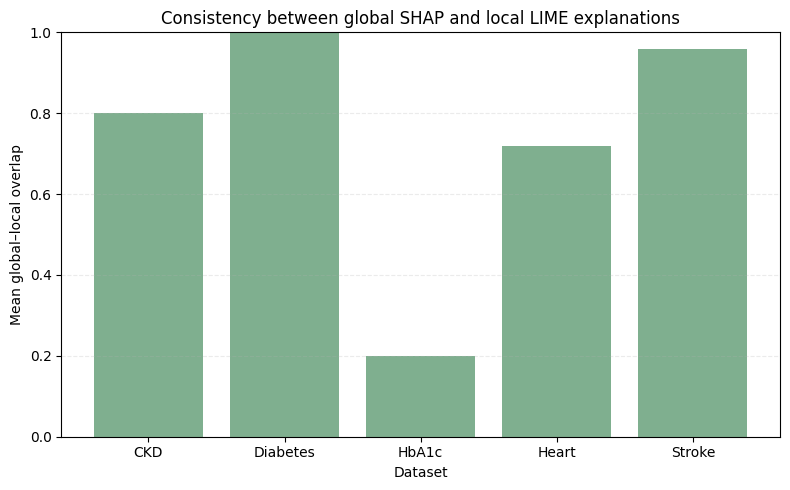

In [110]:
plt.figure(figsize=(8, 5))

plt.bar(
    global_local_plot["Dataset"],
    global_local_plot["GlobalLocalOverlap"],
    color="#7FAF8F"
)

plt.ylim(0, 1)

plt.xlabel("Dataset")
plt.ylabel("Mean global–local overlap")
plt.title("Consistency between global SHAP and local LIME explanations")

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.25
)

plt.tight_layout()
plt.show()

### 1.5.5 Export local XAI tables


In [29]:
local_cases_df.to_csv(
    ANALYSIS_OUT / "representative_cases_all_datasets.csv",
    index=False
)
case_availability.to_csv(
    ANALYSIS_OUT / "local_case_availability.csv",
    index=False
)
lime_summary_df.to_csv(
    ANALYSIS_OUT / "lime_summary_all_datasets.csv",
    index=False
)
lime_with_cases_df.to_csv(
    ANALYSIS_OUT / "lime_by_representative_case.csv",
    index=False
)
case_level_strength_df.to_csv(
    ANALYSIS_OUT / "lime_case_strength_summary.csv",
    index=False
)
outcome_strength_summary.to_csv(
    ANALYSIS_OUT / "lime_correct_vs_error_summary.csv",
    index=False
)
global_local_case_df.to_csv(
    ANALYSIS_OUT / "global_local_overlap_by_case.csv",
    index=False
)


In [35]:
case_type_strength_df = (
    case_level_strength_df
    .groupby(
        ["Dataset", "CaseType"],
        as_index=False
    )
    .agg(
        MeanAbsLIMEWeight=("MeanAbsLIMEWeight", "mean")
    )
)

display(case_type_strength_df.round(4))

,Dataset,CaseType,MeanAbsLIMEWeight
0,CKD,FN,0.0656
1,CKD,FP,0.0723
2,CKD,TN,0.0883
3,CKD,TP,0.0591
4,Diabetes,Borderline,0.0587
5,Diabetes,FN,0.0827
6,Diabetes,FP,0.1283
7,Diabetes,TN,0.0998
8,Diabetes,TP,0.1260
9,HbA1c,Borderline,0.4026


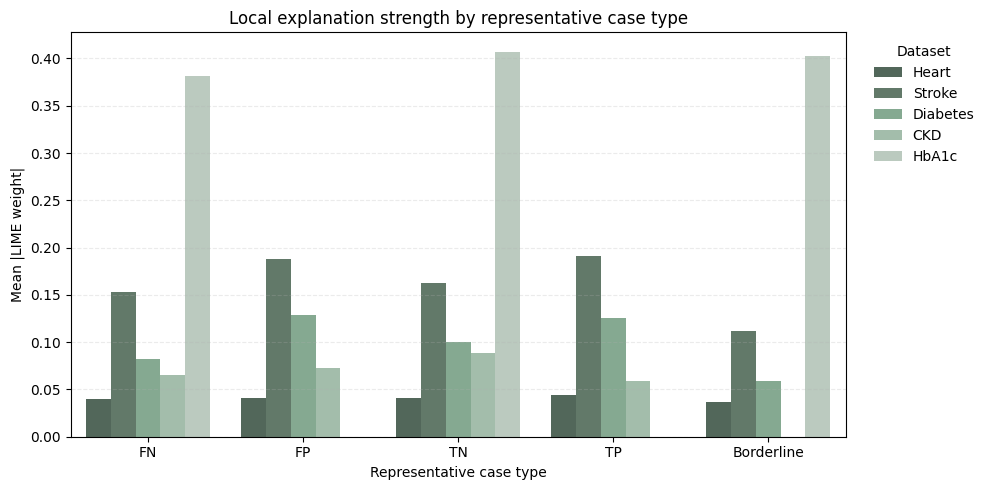

In [109]:
dataset_order = [
    "Heart",
    "Stroke",
    "Diabetes",
    "CKD",
    "HbA1c"
]

plt.figure(figsize=(10, 5))

sns.barplot(
    data=case_type_strength_df,
    x="CaseType",
    y="MeanAbsLIMEWeight",
    hue="Dataset",
    hue_order=dataset_order,
    palette=[
        "#4F6A59",
        "#5E7D68",
        "#7FAF8F",
        "#9FC1AA",
        "#B8CDBE"
    ]
)

plt.xlabel("Representative case type")
plt.ylabel("Mean |LIME weight|")
plt.title("Local explanation strength by representative case type")

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.25
)

plt.legend(
    title="Dataset",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    frameon=False
)

plt.tight_layout()
plt.show()

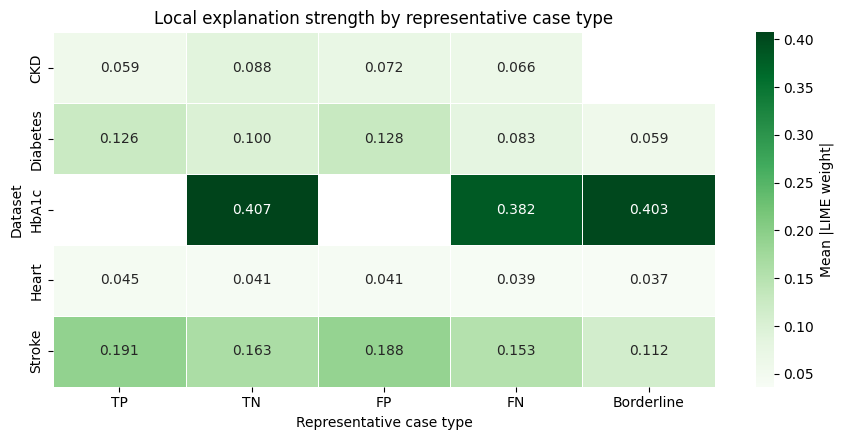

In [52]:
lime_heatmap = (
    case_type_strength_df
    .pivot(
        index="Dataset",
        columns="CaseType",
        values="MeanAbsLIMEWeight"
    )
)

# Logical case order
case_order = [
    c for c in ["TP", "TN", "FP", "FN", "Borderline"]
    if c in lime_heatmap.columns
]

lime_heatmap = lime_heatmap[case_order]

plt.figure(figsize=(9, 4.5))

sns.heatmap(
    lime_heatmap,
    annot=True,
    fmt=".3f",
    cmap="Greens",
    linewidths=0.5,
    cbar_kws={
        "label": "Mean |LIME weight|"
    }
)

plt.xlabel("Representative case type")
plt.ylabel("Dataset")
plt.title(
    "Local explanation strength by representative case type"
)

plt.tight_layout()
plt.show()

Since raw LIME magnitudes are not necessarily directly comparable across different models/datasets, here we have a within-dataset normalized heatmap.

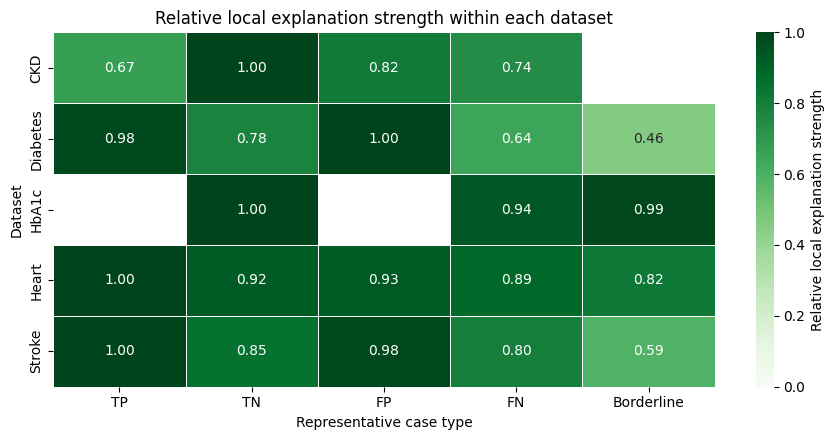

In [51]:
lime_heatmap_normalized = (
    lime_heatmap
    .div(
        lime_heatmap.max(axis=1),
        axis=0
    )
)

plt.figure(figsize=(9, 4.5))

sns.heatmap(
    lime_heatmap_normalized,
    annot=True,
    fmt=".2f",
    cmap="Greens",
    linewidths=0.5,
    vmin=0,
    vmax=1,
    cbar_kws={
        "label": "Relative local explanation strength"
    }
)

plt.xlabel("Representative case type")
plt.ylabel("Dataset")
plt.title(
    "Relative local explanation strength within each dataset"
)

plt.tight_layout()
plt.show()

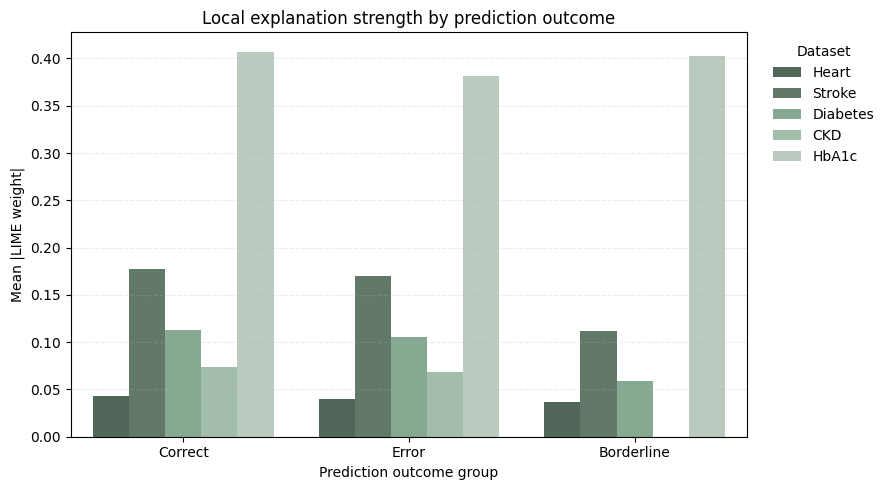

In [108]:
outcome_plot_df = (
    case_level_strength_df
    .groupby(
        ["Dataset", "OutcomeGroup"],
        as_index=False
    )
    .agg(
        MeanAbsLIMEWeight=("MeanAbsLIMEWeight", "mean")
    )
)

dataset_order = [
    "Heart",
    "Stroke",
    "Diabetes",
    "CKD",
    "HbA1c"
]

plt.figure(figsize=(9, 5))

sns.barplot(
    data=outcome_plot_df,
    x="OutcomeGroup",
    y="MeanAbsLIMEWeight",
    hue="Dataset",
    hue_order=dataset_order,
    palette=[
        "#4F6A59",
        "#5E7D68",
        "#7FAF8F",
        "#9FC1AA",
        "#B8CDBE"
    ]
)

plt.xlabel("Prediction outcome group")
plt.ylabel("Mean |LIME weight|")
plt.title("Local explanation strength by prediction outcome")

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.25
)

plt.legend(
    title="Dataset",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    frameon=False
)

plt.tight_layout()
plt.show()

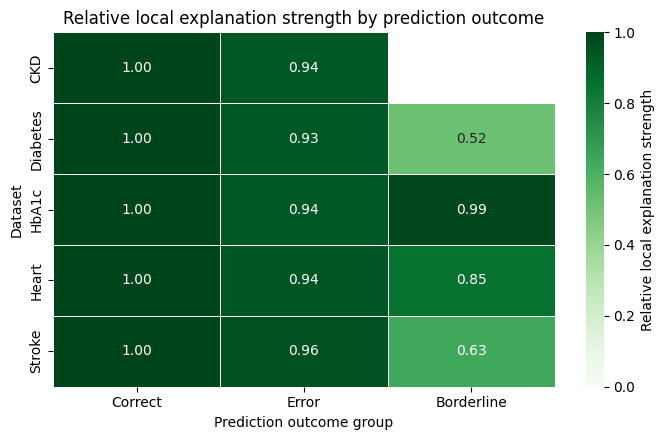

In [49]:
outcome_heatmap = (
    outcome_plot_df
    .pivot(
        index="Dataset",
        columns="OutcomeGroup",
        values="MeanAbsLIMEWeight"
    )
)

outcome_order = [
    c for c in ["Correct", "Error", "Borderline"]
    if c in outcome_heatmap.columns
]

outcome_heatmap = outcome_heatmap[outcome_order]

outcome_heatmap_normalized = (
    outcome_heatmap
    .div(
        outcome_heatmap.max(axis=1),
        axis=0
    )
)

plt.figure(figsize=(7, 4.5))

sns.heatmap(
    outcome_heatmap_normalized,
    annot=True,
    fmt=".2f",
    cmap="Greens",
    linewidths=0.5,
    vmin=0,
    vmax=1,
    cbar_kws={
        "label": "Relative local explanation strength"
    }
)

plt.xlabel("Prediction outcome group")
plt.ylabel("Dataset")
plt.title(
    "Relative local explanation strength by prediction outcome"
)

plt.tight_layout()
plt.show()

# 1.6 Cross-dataset and model-family comparison

Model-family summaries are descriptive. With two linear datasets, two tree datasets, and one statsmodels dataset, they must not be presented as population-level statistical evidence.


In [30]:
summary_rows = []

for dataset in DATASETS:
    metadata = load_metadata(dataset)
    model_name = metadata.get("model", "Unknown")

    if model_name == "BinaryResultsWrapper":
        model_name = "Statsmodels logistic regression"

    if dataset in ["heart", "stroke"]:
        model_family = "Linear classification"
    elif dataset in ["diabetes", "ckd"]:
        model_family = "Tree ensemble"
    else:
        model_family = "Statsmodels logistic regression"

    ranks = global_rank_table(dataset)
    dataset_agreement = agreement_df[
        agreement_df["Dataset"] == DISPLAY_NAMES[dataset]
    ]
    dataset_stability = stability_summary_df[
        stability_summary_df["Dataset"] == DISPLAY_NAMES[dataset]
    ]

    summary_rows.append({
        "Dataset": DISPLAY_NAMES[dataset],
        "Model": model_name,
        "ModelFamily": model_family,
        "FeaturesCompared": len(ranks),
        "MeanCrossMethodRho": (
            dataset_agreement["SpearmanRho"].mean()
        ),
        "MeanStabilityRho": (
            dataset_stability["MeanStabilityRho"].iloc[0]
        ),
        "MeanTopKOverlap": (
            dataset_stability["MeanTopKOverlap"].iloc[0]
        )
    })

cross_dataset_summary_df = pd.DataFrame(summary_rows)

model_family_summary_df = (
    cross_dataset_summary_df
    .groupby("ModelFamily", dropna=False)
    .agg(
        NDatasets=("Dataset", "nunique"),
        MeanFeaturesCompared=("FeaturesCompared", "mean"),
        MeanCrossMethodRho=("MeanCrossMethodRho", "mean"),
        MeanStabilityRho=("MeanStabilityRho", "mean"),
        MeanTopKOverlap=("MeanTopKOverlap", "mean")
    )
    .reset_index()
)

display(cross_dataset_summary_df.round(3))
display(model_family_summary_df.round(3))

cross_dataset_summary_df.to_csv(
    ANALYSIS_OUT / "xai_summary.csv",
    index=False
)
model_family_summary_df.to_csv(
    ANALYSIS_OUT / "model_family_comparison.csv",
    index=False
)


,Dataset,Model,ModelFamily,FeaturesCompared,MeanCrossMethodRho,MeanStabilityRho,MeanTopKOverlap
0,Heart,LogisticRegressionCV,Linear classification,13,0.738,0.945,0.867
1,Stroke,LogisticRegression,Linear classification,7,0.754,0.825,0.800
2,Diabetes,RandomForestClassifier,Tree ensemble,5,1.000,0.940,0.800
3,CKD,RandomForestClassifier,Tree ensemble,24,0.757,0.341,0.567
4,HbA1c,Statsmodels logistic regression,Statsmodels logistic regression,90,0.446,NaN,NaN


,ModelFamily,NDatasets,MeanFeaturesCompared,MeanCrossMethodRho,MeanStabilityRho,MeanTopKOverlap
0,Linear classification,2,10.0,0.746,0.885,0.833
1,Statsmodels logistic regression,1,90.0,0.446,NaN,NaN
2,Tree ensemble,2,14.5,0.879,0.641,0.683


# 1.7 Framework robustness and generalizability

The capability table records what was successfully demonstrated by these five replications. It does not claim support beyond the tested configurations.


In [31]:
framework_summary = pd.DataFrame([
    {
        "Dataset": "Heart",
        "ModelFamily": "Linear classification",
        "InputRepresentation": "NumPy",
        "NativeImportanceDemonstrated": True,
        "PermutationDemonstrated": True,
        "SHAPDemonstrated": True,
        "LIMEDemonstrated": True,
        "StabilityDemonstrated": True
    },
    {
        "Dataset": "Stroke",
        "ModelFamily": "Linear classification",
        "InputRepresentation": "NumPy",
        "NativeImportanceDemonstrated": True,
        "PermutationDemonstrated": True,
        "SHAPDemonstrated": True,
        "LIMEDemonstrated": True,
        "StabilityDemonstrated": True
    },
    {
        "Dataset": "Diabetes",
        "ModelFamily": "Tree ensemble",
        "InputRepresentation": "DataFrame",
        "NativeImportanceDemonstrated": True,
        "PermutationDemonstrated": True,
        "SHAPDemonstrated": True,
        "LIMEDemonstrated": True,
        "StabilityDemonstrated": True
    },
    {
        "Dataset": "CKD",
        "ModelFamily": "Tree ensemble",
        "InputRepresentation": "DataFrame",
        "NativeImportanceDemonstrated": True,
        "PermutationDemonstrated": True,
        "SHAPDemonstrated": True,
        "LIMEDemonstrated": True,
        "StabilityDemonstrated": True
    },
    {
        "Dataset": "HbA1c",
        "ModelFamily": "Statsmodels logistic regression",
        "InputRepresentation": "Patsy design matrix",
        "NativeImportanceDemonstrated": True,
        "PermutationDemonstrated": True,
        "SHAPDemonstrated": True,
        "LIMEDemonstrated": True,
        "StabilityDemonstrated": False
    }
])

framework_limitations = pd.DataFrame([
    {
        "Area": "Prediction task",
        "Limitation": "Evidence is limited to binary classification."
    },
    {
        "Area": "Decision threshold",
        "Limitation": "Representative cases assume the configured binary threshold."
    },
    {
        "Area": "HbA1c stability",
        "Limitation": "No repeated-fit stability output is available."
    },
    {
        "Area": "HbA1c representation",
        "Limitation": "Explanations refer to Patsy design terms and interactions, not only raw variables."
    },
    {
        "Area": "Local cases",
        "Limitation": "Selected representative cases are descriptive and are not a population sample."
    },
    {
        "Area": "Method comparison",
        "Limitation": "Importance magnitudes are not directly comparable across XAI methods."
    }
])

display(framework_summary)
display(framework_limitations)

framework_summary.to_csv(
    ANALYSIS_OUT / "framework_capability_summary.csv",
    index=False
)
framework_limitations.to_csv(
    ANALYSIS_OUT / "framework_limitations.csv",
    index=False
)


,Dataset,ModelFamily,InputRepresentation,NativeImportanceDemonstrated,PermutationDemonstrated,SHAPDemonstrated,LIMEDemonstrated,StabilityDemonstrated
0,Heart,Linear classification,NumPy,True,True,True,True,True
1,Stroke,Linear classification,NumPy,True,True,True,True,True
2,Diabetes,Tree ensemble,DataFrame,True,True,True,True,True
3,CKD,Tree ensemble,DataFrame,True,True,True,True,True
4,HbA1c,Statsmodels logistic regression,Patsy design matrix,True,True,True,True,False


,Area,Limitation
0,Prediction task,Evidence is limited to binary classification.
1,Decision threshold,Representative cases assume the configured bin...
2,HbA1c stability,No repeated-fit stability output is available.
3,HbA1c representation,Explanations refer to Patsy design terms and i...
4,Local cases,Selected representative cases are descriptive ...
5,Method comparison,Importance magnitudes are not directly compara...


In [38]:
print(framework_summary.columns.tolist())
display(framework_summary)

['Dataset', 'ModelFamily', 'InputRepresentation', 'NativeImportanceDemonstrated', 'PermutationDemonstrated', 'SHAPDemonstrated', 'LIMEDemonstrated', 'StabilityDemonstrated']


,Dataset,ModelFamily,InputRepresentation,NativeImportanceDemonstrated,PermutationDemonstrated,SHAPDemonstrated,LIMEDemonstrated,StabilityDemonstrated
0,Heart,Linear classification,NumPy,True,True,True,True,True
1,Stroke,Linear classification,NumPy,True,True,True,True,True
2,Diabetes,Tree ensemble,DataFrame,True,True,True,True,True
3,CKD,Tree ensemble,DataFrame,True,True,True,True,True
4,HbA1c,Statsmodels logistic regression,Patsy design matrix,True,True,True,True,False


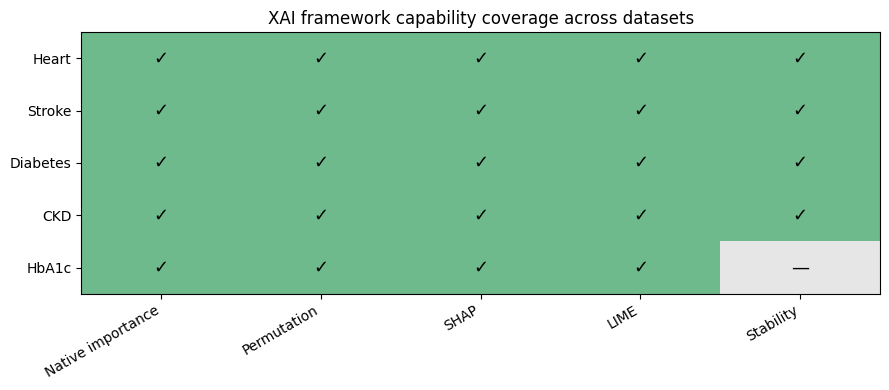

In [50]:
capability_columns = [
    "NativeImportanceDemonstrated",
    "PermutationDemonstrated",
    "SHAPDemonstrated",
    "LIMEDemonstrated",
    "StabilityDemonstrated"
]

capability_labels = [
    "Native importance",
    "Permutation",
    "SHAP",
    "LIME",
    "Stability"
]

capability_matrix = (
    framework_summary
    .set_index("Dataset")[capability_columns]
    .astype(int)
)

from matplotlib.colors import ListedColormap

cmap = ListedColormap([
    "#E6E6E6",   # not demonstrated
    "#6FBA8C"    # demonstrated
])

fig, ax = plt.subplots(figsize=(9, 4))

ax.imshow(
    capability_matrix.values,
    aspect="auto",
    cmap=cmap,
    vmin=0,
    vmax=1
)

ax.set_xticks(range(len(capability_labels)))
ax.set_xticklabels(
    capability_labels,
    rotation=30,
    ha="right"
)

ax.set_yticks(range(len(capability_matrix.index)))
ax.set_yticklabels(capability_matrix.index)

for i in range(capability_matrix.shape[0]):
    for j in range(capability_matrix.shape[1]):

        value = capability_matrix.iloc[i, j]

        ax.text(
            j,
            i,
            "✓" if value == 1 else "—",
            ha="center",
            va="center",
            fontsize=13,
            color="black"
        )

ax.set_title(
    "XAI framework capability coverage across datasets"
)

ax.set_xlabel("")
ax.set_ylabel("")

plt.tight_layout()
plt.show()